# Module 07c: Pandas Advanced Topics

This module covers advanced Pandas operations that are essential for real-world data analysis.

**Prerequisites:** Complete Modules 07a and 07b first.

---

## What You'll Learn

1. [Apply and Transform](#1.-Apply-and-Transform) - Custom functions on data
2. [DateTime Operations](#2.-DateTime-Operations) - Working with dates and times
3. [String Operations](#3.-String-Operations) - Text manipulation
4. [Creating New Columns](#4.-Creating-New-Columns) - Feature engineering
5. [Pivot Tables](#5.-Pivot-Tables) - Reshape data for analysis
6. [Basic Visualization](#6.-Basic-Visualization) - Quick plots
7. [Practice Exercises](#7.-Practice-Exercises)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Sample data
np.random.seed(42)
df = pd.DataFrame({
    'Name': ['Alice', 'Bob', 'Charlie', 'Diana', 'Eve', 'Frank'],
    'Department': ['Sales', 'Engineering', 'Engineering', 'Marketing', 'Sales', 'HR'],
    'Salary': [50000, 75000, 80000, 55000, 52000, 60000],
    'Hire_Date': pd.to_datetime(['2020-01-15', '2019-03-20', '2018-06-10', 
                                  '2021-02-01', '2020-07-15', '2017-11-30'])
})
print(df)

      Name   Department  Salary  Hire_Date
0    Alice        Sales   50000 2020-01-15
1      Bob  Engineering   75000 2019-03-20
2  Charlie  Engineering   80000 2018-06-10
3    Diana    Marketing   55000 2021-02-01
4      Eve        Sales   52000 2020-07-15
5    Frank           HR   60000 2017-11-30


---

# 1. Apply and Transform

The `apply()` method lets you run any function on your data.

## Apply to a Column (Series)

In [3]:
# Simple function: Convert salary to monthly
df['Monthly_Salary'] = df['Salary'].apply(lambda x: x / 12)
print(df[['Name', 'Salary', 'Monthly_Salary']])

      Name  Salary  Monthly_Salary
0    Alice   50000     4166.666667
1      Bob   75000     6250.000000
2  Charlie   80000     6666.666667
3    Diana   55000     4583.333333
4      Eve   52000     4333.333333
5    Frank   60000     5000.000000


In [4]:
# Using a custom function
def salary_grade(salary):
    if salary >= 70000:
        return 'High'
    elif salary >= 55000:
        return 'Medium'
    else:
        return 'Low'

df['Grade'] = df['Salary'].apply(salary_grade)
print(df[['Name', 'Salary', 'Grade']])

      Name  Salary   Grade
0    Alice   50000     Low
1      Bob   75000    High
2  Charlie   80000    High
3    Diana   55000  Medium
4      Eve   52000     Low
5    Frank   60000  Medium


## Apply to Rows

In [5]:
# Apply function to each row (axis=1)
def describe_employee(row):
    return f"{row['Name']} works in {row['Department']}"

df['Description'] = df.apply(describe_employee, axis=1)
print(df[['Name', 'Department', 'Description']])

      Name   Department                   Description
0    Alice        Sales          Alice works in Sales
1      Bob  Engineering      Bob works in Engineering
2  Charlie  Engineering  Charlie works in Engineering
3    Diana    Marketing      Diana works in Marketing
4      Eve        Sales            Eve works in Sales
5    Frank           HR             Frank works in HR


## Using np.where() for Conditional Columns

Faster alternative to apply for simple conditions.

In [6]:
# Create column based on condition
df['High_Earner'] = np.where(df['Salary'] >= 60000, 'Yes', 'No')
print(df[['Name', 'Salary', 'High_Earner']])

      Name  Salary High_Earner
0    Alice   50000          No
1      Bob   75000         Yes
2  Charlie   80000         Yes
3    Diana   55000          No
4      Eve   52000          No
5    Frank   60000         Yes


---

# 2. DateTime Operations

Pandas has powerful tools for working with dates and times.

## Converting to DateTime

In [7]:
# String to datetime
dates = pd.to_datetime(['2024-01-15', '2024-02-20', '2024-03-10'])
print(dates)
print("Type:", type(dates[0]))

DatetimeIndex(['2024-01-15', '2024-02-20', '2024-03-10'], dtype='datetime64[ns]', freq=None)
Type: <class 'pandas._libs.tslibs.timestamps.Timestamp'>


In [8]:
# Different formats
pd.to_datetime('15/01/2024', format='%d/%m/%Y')

Timestamp('2024-01-15 00:00:00')

## Extracting Date Components

In [9]:
print(df[['Name', 'Hire_Date']])
print()

# Extract components using .dt accessor
df['Hire_Year'] = df['Hire_Date'].dt.year
df['Hire_Month'] = df['Hire_Date'].dt.month
df['Hire_Day'] = df['Hire_Date'].dt.day
df['Day_of_Week'] = df['Hire_Date'].dt.day_name()

print(df[['Name', 'Hire_Date', 'Hire_Year', 'Hire_Month', 'Day_of_Week']])

      Name  Hire_Date
0    Alice 2020-01-15
1      Bob 2019-03-20
2  Charlie 2018-06-10
3    Diana 2021-02-01
4      Eve 2020-07-15
5    Frank 2017-11-30

      Name  Hire_Date  Hire_Year  Hire_Month Day_of_Week
0    Alice 2020-01-15       2020           1   Wednesday
1      Bob 2019-03-20       2019           3   Wednesday
2  Charlie 2018-06-10       2018           6      Sunday
3    Diana 2021-02-01       2021           2      Monday
4      Eve 2020-07-15       2020           7   Wednesday
5    Frank 2017-11-30       2017          11    Thursday


## Date Calculations

In [10]:
# Calculate tenure (days since hire)
today = pd.Timestamp.now()
df['Tenure_Days'] = (today - df['Hire_Date']).dt.days
df['Tenure_Years'] = df['Tenure_Days'] / 365

print(df[['Name', 'Hire_Date', 'Tenure_Days', 'Tenure_Years']].round(1))

      Name  Hire_Date  Tenure_Days  Tenure_Years
0    Alice 2020-01-15         2261           6.2
1      Bob 2019-03-20         2562           7.0
2  Charlie 2018-06-10         2845           7.8
3    Diana 2021-02-01         1878           5.1
4      Eve 2020-07-15         2079           5.7
5    Frank 2017-11-30         3037           8.3


## Filtering by Date

In [11]:
# Employees hired after 2020
df[df['Hire_Date'] >= '2020-01-01']

,Name,Department,Salary,Hire_Date,Monthly_Salary,Grade,Description,High_Earner,Hire_Year,Hire_Month,Hire_Day,Day_of_Week,Tenure_Days,Tenure_Years
0,Alice,Sales,50000,2020-01-15,4166.666667,Low,Alice works in Sales,No,2020,1,15,Wednesday,2261,6.194521
3,Diana,Marketing,55000,2021-02-01,4583.333333,Medium,Diana works in Marketing,No,2021,2,1,Monday,1878,5.145205
4,Eve,Sales,52000,2020-07-15,4333.333333,Low,Eve works in Sales,No,2020,7,15,Wednesday,2079,5.695890


In [12]:
# Employees hired in 2019 or 2020
df[df['Hire_Year'].isin([2019, 2020])]

,Name,Department,Salary,Hire_Date,Monthly_Salary,Grade,Description,High_Earner,Hire_Year,Hire_Month,Hire_Day,Day_of_Week,Tenure_Days,Tenure_Years
0,Alice,Sales,50000,2020-01-15,4166.666667,Low,Alice works in Sales,No,2020,1,15,Wednesday,2261,6.194521
1,Bob,Engineering,75000,2019-03-20,6250.000000,High,Bob works in Engineering,Yes,2019,3,20,Wednesday,2562,7.019178
4,Eve,Sales,52000,2020-07-15,4333.333333,Low,Eve works in Sales,No,2020,7,15,Wednesday,2079,5.695890


---

# 3. String Operations

Use the `.str` accessor for string operations.

In [ ]:
# Sample data
df_text = pd.DataFrame({
    'Email': ['alice@company.com', 'bob@company.com', 'charlie@gmail.com'],
    'Full_Name': ['Alice Smith', 'Bob Johnson', 'Charlie Brown']
})
print(df_text)

In [ ]:
# Case conversion
print("Upper:", df_text['Full_Name'].str.upper().tolist())
print("Lower:", df_text['Full_Name'].str.lower().tolist())

In [ ]:
# Split strings
df_text['First_Name'] = df_text['Full_Name'].str.split().str[0]
df_text['Last_Name'] = df_text['Full_Name'].str.split().str[1]
print(df_text)

In [ ]:
# Extract domain from email
df_text['Domain'] = df_text['Email'].str.split('@').str[1]
print(df_text[['Email', 'Domain']])

In [ ]:
# String contains
df_text[df_text['Email'].str.contains('company')]

---

# 4. Creating New Columns

Feature engineering - creating new columns from existing ones.

In [ ]:
# Reset our main df
df = pd.DataFrame({
    'Product': ['A', 'B', 'C', 'D'],
    'Price': [100, 200, 150, 300],
    'Quantity': [10, 5, 8, 3]
})

# Simple calculation
df['Revenue'] = df['Price'] * df['Quantity']
print(df)

In [ ]:
# Percentage of total
df['Revenue_Pct'] = (df['Revenue'] / df['Revenue'].sum() * 100).round(1)
print(df)

In [ ]:
# Binning continuous values
df['Price_Category'] = pd.cut(df['Price'], 
                               bins=[0, 150, 250, 500],
                               labels=['Low', 'Medium', 'High'])
print(df)

---

# 5. Pivot Tables

Reshape data for analysis (like Excel pivot tables).

In [ ]:
# Sales data
sales = pd.DataFrame({
    'Region': ['North', 'North', 'South', 'South', 'East', 'East'],
    'Product': ['A', 'B', 'A', 'B', 'A', 'B'],
    'Sales': [100, 150, 200, 120, 180, 90],
    'Units': [10, 15, 20, 12, 18, 9]
})
print(sales)

In [ ]:
# Pivot table: Sales by Region and Product
pivot = sales.pivot_table(values='Sales', 
                          index='Region', 
                          columns='Product',
                          aggfunc='sum')
print(pivot)

In [ ]:
# Multiple aggregations
pivot = sales.pivot_table(values='Sales', 
                          index='Region', 
                          columns='Product',
                          aggfunc=['sum', 'mean'],
                          margins=True)  # Add totals
print(pivot)

---

# 6. Basic Visualization

Pandas integrates with Matplotlib for quick visualizations.

## Line Plot

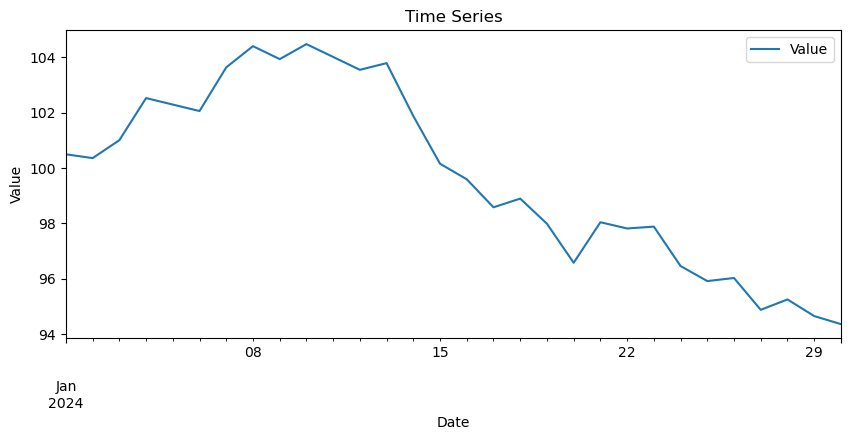

In [13]:
# Time series data
dates = pd.date_range('2024-01-01', periods=30, freq='D')
ts = pd.DataFrame({
    'Date': dates,
    'Value': np.random.randn(30).cumsum() + 100
})
ts.set_index('Date', inplace=True)

# Line plot
ts.plot(figsize=(10, 4), title='Time Series')
plt.ylabel('Value')
plt.show()

## Bar Chart

In [ ]:
# Category counts
dept_counts = pd.Series({'Engineering': 50, 'Sales': 35, 'Marketing': 25, 'HR': 15})

dept_counts.plot(kind='bar', figsize=(8, 4), title='Employees by Department', color='steelblue')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

## Histogram

In [ ]:
# Distribution of values
salaries = pd.Series(np.random.normal(60000, 15000, 200))

salaries.plot(kind='hist', bins=20, figsize=(8, 4), 
              title='Salary Distribution', edgecolor='black')
plt.xlabel('Salary')
plt.show()

## Scatter Plot

In [ ]:
# Relationship between variables
data = pd.DataFrame({
    'Experience': np.random.randint(1, 20, 50),
    'Salary': np.random.randint(40000, 120000, 50)
})
# Add correlation
data['Salary'] = data['Experience'] * 4000 + np.random.normal(30000, 5000, 50)

data.plot(kind='scatter', x='Experience', y='Salary', 
          figsize=(8, 5), title='Experience vs Salary')
plt.show()

## Box Plot

In [ ]:
# Distribution by category
dept_salaries = pd.DataFrame({
    'Engineering': np.random.normal(80000, 10000, 30),
    'Sales': np.random.normal(55000, 8000, 30),
    'Marketing': np.random.normal(60000, 12000, 30)
})

dept_salaries.plot(kind='box', figsize=(8, 5), title='Salary by Department')
plt.ylabel('Salary')
plt.show()

---

# 7. Practice Exercises

### Exercise 1: DateTime Analysis

Given order data:
1. Convert Order_Date to datetime
2. Extract month and day of week
3. Find orders placed on weekends
4. Calculate total revenue per month

In [ ]:
orders = pd.DataFrame({
    'Order_ID': range(1, 11),
    'Order_Date': ['2024-01-15', '2024-01-20', '2024-02-05', '2024-02-14', 
                   '2024-03-01', '2024-03-15', '2024-03-22', '2024-04-01',
                   '2024-04-15', '2024-04-30'],
    'Amount': [150, 200, 300, 175, 225, 400, 180, 290, 350, 275]
})

# Write your code here


### Exercise 2: Apply Custom Functions

Given customer data:
1. Create a function to classify age groups (Young: <30, Adult: 30-50, Senior: >50)
2. Apply it to create an Age_Group column
3. Calculate average spending by age group

In [ ]:
customers = pd.DataFrame({
    'Customer_ID': range(1, 9),
    'Age': [25, 35, 55, 42, 28, 61, 33, 48],
    'Spending': [500, 750, 1200, 900, 400, 1500, 650, 1100]
})

# Write your code here


### Exercise 3: Visualization

Using the sales data:
1. Create a bar chart of sales by region
2. Create a scatter plot of Units vs Sales
3. Create a pivot table and visualize it as a heatmap

In [ ]:
sales = pd.DataFrame({
    'Region': ['North', 'North', 'South', 'South', 'East', 'East', 'West', 'West'],
    'Product': ['A', 'B', 'A', 'B', 'A', 'B', 'A', 'B'],
    'Sales': [100, 150, 200, 120, 180, 90, 160, 140],
    'Units': [10, 15, 20, 12, 18, 9, 16, 14]
})

# Write your code here


---

## Summary

| Concept | Key Methods |
|---------|-------------|
| **Apply** | `df.apply(func)`, `df.apply(func, axis=1)` |
| **DateTime** | `pd.to_datetime()`, `.dt.year`, `.dt.month`, `.dt.day_name()` |
| **Strings** | `.str.upper()`, `.str.split()`, `.str.contains()` |
| **New Columns** | `df['new'] = calculation`, `pd.cut()`, `np.where()` |
| **Pivot Tables** | `pd.pivot_table(values, index, columns, aggfunc)` |
| **Visualization** | `.plot(kind='line/bar/hist/scatter/box')` |

**Congratulations!** You've completed the Pandas module. You now have the skills to:
- Load and save data from various sources
- Explore and understand your datasets
- Filter, sort, and transform data
- Handle missing values and duplicates
- Group and aggregate data
- Merge multiple datasets
- Create visualizations

**Practice:** Complete the remaining exercises (07_7, 07_8, 07_9) and the Pandas Project!